<a href="https://colab.research.google.com/github/oxanaadry-svg/python_sis_26_2/blob/oxana_silva/aula_oxana_silva_aula12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Instala a biblioteca openpyxl
%pip install -q openpyxl

# Importa a biblioteca utilizada para criar planilhas
from openpyxl import Workbook

# Cria uma pasta de trabalho
planilha = Workbook()

# Seleciona a aba ativa e define seu nome
aba = planilha.active
aba.title = "Servidores"

# Cria o cabecalho da planilha
cabecalho = [
    "Hostname",
    "IP",
    "Memoria (GB)",
    "Uso de Disco (%)",
    "Status"
]

# Adiciona o cabecalho na primeira linha
aba.append(cabecalho)

# Salva a planilha no diretorio de execucao
planilha.save("inventario_servidores.xlsx")

# Exibe uma mensagem de confirmacao
print("Planilha criada com sucesso!")


Planilha criada com sucesso!


In [ ]:

# Instala a biblioteca openpyxl
%pip install -q openpyxl

# Importa a biblioteca utilizada para criar planilhas
from openpyxl import Workbook

# Cria uma pasta de trabalho
planilha = Workbook()

# Seleciona a aba ativa
aba = planilha.active
aba.title = "Servidores"

# Cria o cabecalho da planilha
cabecalho = [
    "Hostname",
    "IP",
    "Memoria (GB)",
    "Uso de Disco (%)",
    "Status"
]

# Adiciona o cabecalho
aba.append(cabecalho)

# Dados dos servidores
servidores = [
    ["Servidor01", "192.168.0.1", 16, 75, "Ativo"],
    ["Servidor02", "192.168.0.2", 32, 85, "Ativo"],
    ["Servidor03", "192.168.0.3", 8, 90, "Ativo"],
    ["Servidor04", "192.168.0.4", 16, 60, "Ativo"]
]

# Adiciona os dados na planilha
for servidor in servidores:
    aba.append(servidor)

# Percorre os dados dos servidores
for linha in range(2, aba.max_row + 1):

    # Pega o nome do servidor
    hostname = aba.cell(row=linha, column=1).value

    # Pega o uso de disco
    uso_disco = aba.cell(row=linha, column=4).value

    # Verifica se o uso de disco e maior ou igual a 80%
    if uso_disco >= 80:
        print(
            f"ALERTA: {hostname} precisa de expansao "
            f"de armazenamento! Uso: {uso_disco}%"
        )

# Salva a planilha
planilha.save("inventario_servidores.xlsx")

print("Inventario salvo com sucesso!")


ALERTA: Servidor02 precisa de expansao de armazenamento! Uso: 85%
ALERTA: Servidor03 precisa de expansao de armazenamento! Uso: 90%
Inventario salvo com sucesso!


In [ ]:

# Abre o arquivo de log e trata possiveis erros
try:

    # Abre o arquivo no modo de leitura
    with open("log.txt", "r", encoding="utf-8") as arquivo:

        # Percorre cada linha do arquivo
        for linha in arquivo:

            # Remove espacos e quebras de linha
            linha = linha.strip()

            # Verifica se a linha possui algum nivel de evento
            if "INFO" in linha:
                tipo_evento = "INFO"

            elif "AVISO" in linha:
                tipo_evento = "AVISO"

            elif "ERRO" in linha:
                tipo_evento = "ERRO"

            else:
                tipo_evento = "DESCONHECIDO"

            # Exibe o nivel do evento
            print("Tipo de evento:", tipo_evento)

            # Exibe a linha completa do log
            print("Mensagem:", linha)

except FileNotFoundError:
    print("Erro: O arquivo log.txt nao foi encontrado.")


Erro: O arquivo log.txt nao foi encontrado.


In [ ]:

# Abre o arquivo no modo de leitura e escrita
with open("log.txt", "a+") as log:

    # Grava as informacoes no arquivo
    log.write("""2026-10-14 08:30:15 - INFO - Sistema inicializado com sucesso
2026-10-14 08:31:02 - INFO - Usuario 'admin' realizou login
2026-10-14 08:35:22 - AVISO - Tentativa de acesso com senha incorreta: usuario 'bat'
2026-10-14 08:35:40 - SUCESSO - Usuario 'bat' realizou login
2026-10-14 08:40:11 - ERRO - Falha ao conectar ao banco de dados: timeout
2026-10-14 08:42:00 - INFO - Conexao reestabelecida
""")

    # Volta ao inicio do arquivo
    log.seek(0)

    # Faz a leitura do conteudo
    conteudo = log.read()

    # Mostra o conteudo na tela
    print(conteudo)


2026-10-14 08:30:15 - INFO - Sistema inicializado com sucesso
2026-10-14 08:31:02 - INFO - Usuario 'admin' realizou login
2026-10-14 08:35:22 - AVISO - Tentativa de acesso com senha incorreta: usuario 'bat'
2026-10-14 08:35:40 - SUCESSO - Usuario 'bat' realizou login
2026-10-14 08:40:11 - ERRO - Falha ao conectar ao banco de dados: timeout
2026-10-14 08:42:00 - INFO - Conexao reestabelecida



In [ ]:

# Importa a biblioteca para criar planilhas Excel
from openpyxl import Workbook

# Abre o arquivo de log
try:
    with open("log.txt", "r", encoding="utf-8") as log:

        # Cria uma nova planilha
        planilha = Workbook()
        aba = planilha.active
        aba.title = "Auditoria Logs"

        # Cria o cabecalho
        aba.append(["Data/Hora", "Tipo de Evento", "Mensagem"])

        # Percorre cada linha do arquivo
        for linha in log:

            # Remove espacos e quebras de linha
            linha = linha.strip()

            # Separa as informacoes
            partes = linha.split(" - ", 2)

            # Verifica se a linha possui as tres partes
            if len(partes) == 3:

                data_hora = partes[0]
                tipo_evento = partes[1]
                mensagem = partes[2]

                # Adiciona os dados na planilha
                aba.append([
                    data_hora,
                    tipo_evento,
                    mensagem
                ])

        # Salva o arquivo Excel
        planilha.save("auditoria_logs.xlsx")

        print("Planilha auditoria_logs.xlsx criada com sucesso!")

except FileNotFoundError:
    print("Erro: O arquivo log.txt nao foi encontrado.")


Planilha auditoria_logs.xlsx criada com sucesso!


In [ ]:

# Instala a biblioteca psutil
%pip install -q psutil

# Importa a biblioteca
import psutil

# Captura o uso da CPU
uso_cpu = psutil.cpu_percent(interval=1)

# Captura o uso da memoria RAM
memoria = psutil.virtual_memory()

# Mostra as informacoes no terminal
print("================================")
print("   METRICAS DE HARDWARE")
print("================================")

print(f"Uso da CPU: {uso_cpu}%")

print(f"Uso da Memoria RAM: {memoria.percent}%")

print(f"Memoria total: {memoria.total / (1024 ** 3):.2f} GB")

print(f"Memoria disponivel: {memoria.available / (1024 ** 3):.2f} GB")


   METRICAS DE HARDWARE
Uso da CPU: 3.5%
Uso da Memoria RAM: 9.4%
Memoria total: 12.67 GB
Memoria disponivel: 11.49 GB


In [ ]:

# Instala a biblioteca psutil
%pip install -q psutil

# Importa as bibliotecas
import psutil
import time

# Exibe o titulo
print("================================")
print("   COLETA DE METRICAS")
print("================================")

# Cria um ciclo com 5 iteracoes
for i in range(5):

    # Captura o uso da CPU
    uso_cpu = psutil.cpu_percent(interval=1)

    # Captura o uso da memoria RAM
    memoria = psutil.virtual_memory()

    # Exibe os resultados
    print(f"\nAmostragem {i + 1}")
    print(f"Uso da CPU: {uso_cpu}%")
    print(f"Uso da Memoria RAM: {memoria.percent}%")

    # Aguarda 1 segundo antes da proxima captura
    time.sleep(1)

print("\nColeta finalizada!")


   COLETA DE METRICAS

Amostragem 1
Uso da CPU: 5.5%
Uso da Memoria RAM: 9.7%

Amostragem 2
Uso da CPU: 20.6%
Uso da Memoria RAM: 9.7%

Amostragem 3
Uso da CPU: 5.5%
Uso da Memoria RAM: 9.4%

Amostragem 4
Uso da CPU: 4.5%
Uso da Memoria RAM: 9.2%

Amostragem 5
Uso da CPU: 28.9%
Uso da Memoria RAM: 9.4%

Coleta finalizada!


In [ ]:

# Instala a biblioteca psutil
%pip install -q psutil

# Importa as bibliotecas
import psutil
import time

# Define o caminho do arquivo CSV
caminho = "telemetria_sistema.csv"

# Cria o arquivo e grava o cabecalho
with open(caminho, "w", encoding="utf-8") as arquivo:
    arquivo.write("Iteracao,Uso_CPU_Pct,Uso_RAM_Pct\n")

# Exibe uma mensagem
print("Arquivo CSV criado com sucesso!")

# Realiza 5 coletas de metricas
for i in range(5):

    # Captura o uso da CPU
    uso_cpu = psutil.cpu_percent(interval=1)

    # Captura o uso da memoria RAM
    memoria = psutil.virtual_memory()

    # Mostra os resultados
    print(f"\nAmostragem {i + 1}")
    print(f"Uso da CPU: {uso_cpu}%")
    print(f"Uso da RAM: {memoria.percent}%")

    # Aguarda 1 segundo
    time.sleep(1)

print("\nColeta finalizada!")


Arquivo CSV criado com sucesso!

Amostragem 1
Uso da CPU: 58.1%
Uso da RAM: 9.1%

Amostragem 2
Uso da CPU: 4.0%
Uso da RAM: 8.9%

Amostragem 3
Uso da CPU: 7.5%
Uso da RAM: 8.9%

Amostragem 4
Uso da CPU: 2.0%
Uso da RAM: 8.9%

Amostragem 5
Uso da CPU: 8.6%
Uso da RAM: 8.9%

Coleta finalizada!


In [ ]:

# Instala a biblioteca psutil
%pip install -q psutil

# Importa as bibliotecas
import psutil
import time

# Define o caminho do arquivo CSV
caminho = "telemetria_sistema.csv"

# Cria o arquivo e grava o cabecalho
with open(caminho, "w", encoding="utf-8") as arquivo:
    arquivo.write("Iteracao,Uso_CPU_Pct,Uso_RAM_Pct\n")

# Exibe uma mensagem
print("Arquivo CSV criado com sucesso!")

# Realiza 5 coletas de metricas
for i in range(5):

    # Captura o uso da CPU
    uso_cpu = psutil.cpu_percent(interval=1)

    # Captura o uso da memoria RAM
    memoria = psutil.virtual_memory()

    # Guarda os valores coletados
    uso_ram = memoria.percent

    # Abre o arquivo no modo de anexacao
    with open(caminho, "a", encoding="utf-8") as arquivo:

        # Grava os dados da amostragem
        arquivo.write(f"{i + 1},{uso_cpu},{uso_ram}\n")

    # Mostra os resultados
    print(f"\nAmostragem {i + 1}")
    print(f"Uso da CPU: {uso_cpu}%")
    print(f"Uso da RAM: {uso_ram}%")

    # Aguarda 1 segundo
    time.sleep(1)

print("\nColeta finalizada!")
print("Dados salvos em telemetria_sistema.csv")


Arquivo CSV criado com sucesso!

Amostragem 1
Uso da CPU: 3.5%
Uso da RAM: 9.4%

Amostragem 2
Uso da CPU: 2.0%
Uso da RAM: 9.4%

Amostragem 3
Uso da CPU: 2.0%
Uso da RAM: 9.4%

Amostragem 4
Uso da CPU: 57.3%
Uso da RAM: 9.5%

Amostragem 5
Uso da CPU: 2.0%
Uso da RAM: 9.5%

Coleta finalizada!
Dados salvos em telemetria_sistema.csv


In [ ]:

# Instala a biblioteca pandas
%pip install -q pandas

# Importa a biblioteca
import pandas as pd

# Define o caminho do arquivo
caminho = "telemetria_sistema.csv"

# Faz a leitura do arquivo CSV
dados = pd.read_csv(caminho)

# Exibe os dados na tela
print("================================")
print("   METRICAS DE HARDWARE")
print("================================")

print(dados)


   METRICAS DE HARDWARE
   Iteracao  Uso_CPU_Pct  Uso_RAM_Pct
0         1          3.5          9.4
1         2          2.0          9.4
2         3          2.0          9.4
3         4         57.3          9.5
4         5          2.0          9.5


In [ ]:

# Importa a biblioteca pandas
import pandas as pd

# Define o caminho do arquivo
caminho = "telemetria_sistema.csv"

# Faz a leitura do arquivo CSV
dados = pd.read_csv(caminho)

# Calcula a media de uso da CPU
media_cpu = dados["Uso_CPU_Pct"].mean()

# Calcula a media de uso da memoria RAM
media_ram = dados["Uso_RAM_Pct"].mean()

# Exibe o resumo descritivo
print("================================")
print("   RESUMO DE METRICAS")
print("================================")

print(f"Media de uso da CPU: {media_cpu:.2f}%")
print(f"Media de uso da RAM: {media_ram:.2f}%")

print("================================")


   RESUMO DE METRICAS
Media de uso da CPU: 13.36%
Media de uso da RAM: 9.44%


   RESUMO DE METRICAS
Media de uso da CPU: 13.36%
Media de uso da RAM: 9.44%


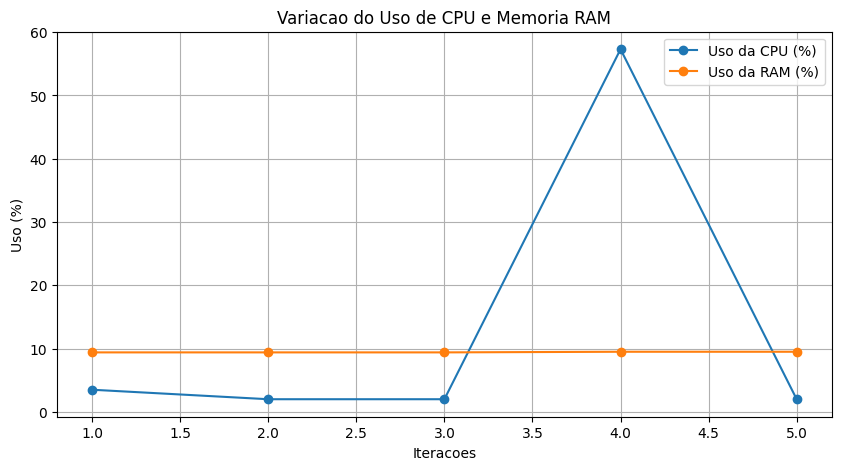

In [ ]:

# Importa as bibliotecas
import pandas as pd
import matplotlib.pyplot as plt

# Define o caminho do arquivo
caminho = "telemetria_sistema.csv"

# Faz a leitura do arquivo CSV
dados = pd.read_csv(caminho)

# Calcula a media de uso da CPU
media_cpu = dados["Uso_CPU_Pct"].mean()

# Calcula a media de uso da RAM
media_ram = dados["Uso_RAM_Pct"].mean()

# Exibe o resumo das metricas
print("================================")
print("   RESUMO DE METRICAS")
print("================================")
print(f"Media de uso da CPU: {media_cpu:.2f}%")
print(f"Media de uso da RAM: {media_ram:.2f}%")

# Cria o grafico de linha
plt.figure(figsize=(10, 5))

# Adiciona a linha de uso da CPU
plt.plot(
    dados["Iteracao"],
    dados["Uso_CPU_Pct"],
    marker="o",
    label="Uso da CPU (%)"
)

# Adiciona a linha de uso da RAM
plt.plot(
    dados["Iteracao"],
    dados["Uso_RAM_Pct"],
    marker="o",
    label="Uso da RAM (%)"
)

# Define o titulo e os nomes dos eixos
plt.title("Variacao do Uso de CPU e Memoria RAM")
plt.xlabel("Iteracoes")
plt.ylabel("Uso (%)")

# Adiciona legenda e grade
plt.legend()
plt.grid(True)

# Exibe o grafico
plt.show()
